# Homework 2 — corrected assignment

This notebook answers Problems 1–3 using the supplied corrected assignment and data.
All reported results are produced by the code below. Random seeds and splits are fixed.
The supplied helper scripts are optional; the implementations here are self-contained.

**To rerun:** install `numpy pandas scipy scikit-learn matplotlib torch pyarrow ipykernel`,
put the five data files beside this notebook (or in `data/`), and run all cells in order.
The Problem 3 prediction CSVs are written beside the notebook, without a header or index,
with exactly one prediction per input row. CPU training can take several minutes.

In [1]:
from pathlib import Path
import copy, json, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, brier_score_loss, log_loss, accuracy_score
from sklearn.calibration import calibration_curve
import sklearn
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display, Markdown

SEED = 42
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_all()
torch.set_num_threads(2)
DEVICE = torch.device('cpu')  # fixed CPU execution for reproducibility
DATA = next((p for p in [Path('data'), Path('.'), Path('../upload'), Path('upload')]
             if (p/'taxi_trips.parquet').exists()), None)
assert DATA is not None, 'Put the five provided datasets beside the notebook or in data/.'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def showfig(name):
    plt.tight_layout(); plt.savefig(FIG/name, dpi=150, bbox_inches='tight'); plt.show(); plt.close()
print({'Python':platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__,
       'scipy':scipy.__version__, 'scikit-learn':sklearn.__version__, 'torch':torch.__version__})

{'Python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'scikit-learn': '1.8.0', 'torch': '2.15.0+cpu'}


## Problem 1: Conditional mean and uncertainty

### (a) Link functions
Write the two outputs as $g(x)=(a(x),b(x))$. Use
\[
f_\mu(x)=a(x),\qquad f_\sigma(x)=\operatorname{softplus}(b(x))+\epsilon,
\quad \operatorname{softplus}(b)=\log(1+e^b).
\]
The mean can be any real number, while the standard deviation must be positive.
The small constant $\epsilon>0$ prevents division by zero. An exponential link for
the standard deviation would also work, but softplus grows more gently.

### (b) Loss
Under $Y\mid X=x\sim N(f_\mu(x),f_\sigma(x)^2)$, minimize the average Gaussian negative log-likelihood:
\[
\mathcal L=\frac1n\sum_{i=1}^n\left[
\frac12\log(2\pi)+\log f_\sigma(x_i)
+\frac{(y_i-f_\mu(x_i))^2}{2f_\sigma(x_i)^2}\right].
\]
The squared residual penalizes a poor mean prediction. The log-standard-deviation term
prevents the model from reducing that penalty simply by predicting unlimited uncertainty.

### (c) Data, baselines, and training
I use a random 70/15/15 train/validation/test split. The features are already standardized
in the supplied file, so I use them as given. I standardize the target using only the
training mean and standard deviation, and convert all final predictions back to minutes.
This changes NLL by the constant $\log(s_y)$ and does not change which parameters minimize it.
No trips are removed or winsorized.

Baselines are a constant Gaussian and a linear ridge mean with a constant residual
standard deviation estimated on training data. The MLP has two ReLU hidden layers
and separate mean and standard-deviation outputs. I compare hidden widths 64 and 128,
using validation NLL for both early stopping and width selection. The test set is used
only after that selection. The evaluation concerns random held-out trips, rather than
generalization to future dates or unseen cities.

Split sizes: {'train': 366487, 'validation': 78533, 'test': 78534}


,count,mean,std,min,25%,50%,75%,max
pickup_longitude,523554.0,-1.748678e-10,1.000000,-33.360661,-0.536909,-0.154072,0.370370,29.372255
pickup_latitude,523554.0,-1.748678e-10,1.000000,-14.299238,-0.573135,0.071330,0.630659,13.277072
dropoff_longitude,523554.0,5.828926e-11,1.000000,-33.478436,-0.575492,-0.146892,0.428622,52.664162
dropoff_latitude,523554.0,2.914463e-10,1.000000,-12.746450,-0.554024,0.058973,0.609775,20.875807
trip_duration,523554.0,1.041305e+01,7.754068,0.033386,4.749882,8.631456,13.928152,227.942612
min_of_day,523554.0,1.165785e-10,1.000000,-2.209709,-0.716813,0.100352,0.838942,1.559200
day_of_week,523554.0,1.393113e-08,1.000000,-1.557377,-1.047619,-0.028101,0.991416,1.501174
day_of_year,523554.0,9.326282e-10,1.000000,-1.745299,-0.853888,-0.001234,0.851420,1.762210


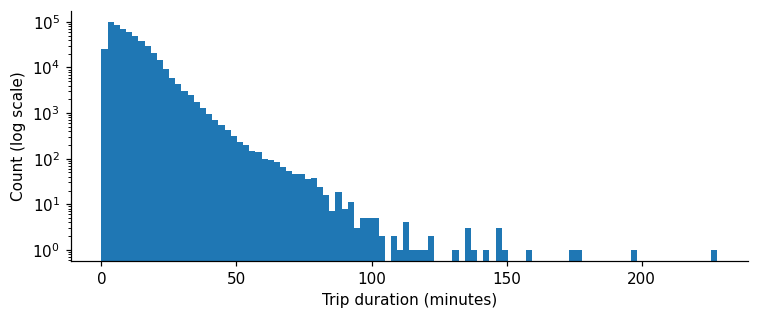

In [2]:
taxi = pd.read_parquet(DATA/'taxi_trips.parquet').reset_index(drop=True)
assert taxi.shape[1] == 8 and not taxi.isna().any().any()
taxi_features = [c for c in taxi.columns if c != 'trip_duration']
Xtaxi = taxi[taxi_features].to_numpy(np.float32)
ytaxi = taxi.trip_duration.to_numpy(np.float32)
itr, irest = train_test_split(np.arange(len(taxi)), test_size=.30, random_state=SEED)
iva, ite = train_test_split(irest, test_size=.50, random_state=SEED)
Xt, Xv, Xe = Xtaxi[itr], Xtaxi[iva], Xtaxi[ite]
yt, yv, ye = ytaxi[itr], ytaxi[iva], ytaxi[ite]
ym, ys = float(yt.mean()), float(yt.std())
zt, zv = (yt-ym)/ys, (yv-ym)/ys
print('Split sizes:', {'train':len(itr), 'validation':len(iva), 'test':len(ite)})
display(taxi.describe().T)
plt.figure(figsize=(7,3)); plt.hist(ytaxi,bins=100); plt.yscale('log')
plt.xlabel('Trip duration (minutes)'); plt.ylabel('Count (log scale)'); showfig('q1_duration.png')

taxi width=64, epoch=5, val NLL=2.7135
taxi width=64, epoch=10, val NLL=2.6847
taxi width=64, epoch=15, val NLL=2.6653
taxi width=64, epoch=20, val NLL=2.6575
taxi width=64, epoch=25, val NLL=2.6499
taxi width=64, epoch=30, val NLL=2.6490
taxi width=128, epoch=5, val NLL=2.7058
taxi width=128, epoch=10, val NLL=2.6749
taxi width=128, epoch=15, val NLL=2.6571
taxi width=128, epoch=20, val NLL=2.6362
taxi width=128, epoch=25, val NLL=2.6424
taxi width=128, epoch=30, val NLL=2.6390
taxi width=128, epoch=35, val NLL=2.6265


,width,validation_NLL,best_epoch
0,64,2.646460,26
1,128,2.624821,32


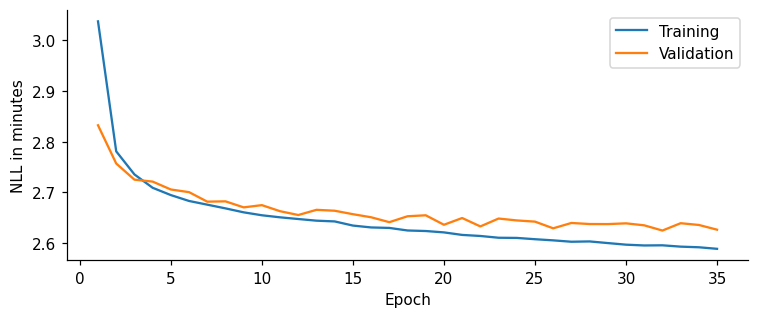

In [3]:
class GaussianMLP(nn.Module):
    def __init__(self, n_features, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features,width), nn.ReLU(),
                                 nn.Linear(width,width), nn.ReLU(), nn.Linear(width,2))
    def forward(self, x):
        o = self.net(x)
        return o[:,0], F.softplus(o[:,1]) + 1e-3

def gaussian_nll_torch(mu, sigma, y):
    return (0.5*np.log(2*np.pi) + sigma.log() + 0.5*((y-mu)/sigma)**2).mean()

def gaussian_predict(model, X, batch=8192):
    model.eval(); means=[]; stds=[]
    with torch.no_grad():
        for j in range(0,len(X),batch):
            m,s = model(torch.as_tensor(X[j:j+batch],dtype=torch.float32,device=DEVICE))
            means.append(m.cpu().numpy()); stds.append(s.cpu().numpy())
    return np.concatenate(means)*ys+ym, np.concatenate(stds)*ys

def nll_np(y,mu,sigma):
    return float(np.mean(.5*np.log(2*np.pi)+np.log(sigma)+.5*((y-mu)/sigma)**2))

def train_gaussian(width, epochs=35, patience=6):
    seed_all()
    model=GaussianMLP(Xt.shape[1],width).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-5)
    xx=torch.from_numpy(Xt).to(DEVICE); zz=torch.from_numpy(zt).to(DEVICE)
    history=[]; best=np.inf; state=None; stale=0
    for epoch in range(epochs):
        model.train(); order=torch.randperm(len(xx),device=DEVICE); total=0.
        for ids in order.split(2048):
            opt.zero_grad(); mu,sigma=model(xx[ids]); loss=gaussian_nll_torch(mu,sigma,zz[ids])
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),10.); opt.step()
            total+=loss.item()*len(ids)
        mv,sv=gaussian_predict(model,Xv); val=nll_np(yv,mv,sv)
        history.append((epoch+1,total/len(xx)+np.log(ys),val))
        if val < best-1e-5:
            best=val; state=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if (epoch+1)%5==0: print(f'taxi width={width}, epoch={epoch+1}, val NLL={val:.4f}',flush=True)
        if stale>=patience: break
    model.load_state_dict(state)
    return model,pd.DataFrame(history,columns=['epoch','train_nll','val_nll'])

taxi_candidates={}; taxi_sweep=[]
for width in [64,128]:
    model,hist=train_gaussian(width)
    taxi_candidates[width]=(model,hist)
    taxi_sweep.append({'width':width,'validation_NLL':hist.val_nll.min(),
                       'best_epoch':int(hist.loc[hist.val_nll.idxmin(),'epoch'])})
taxi_sweep=pd.DataFrame(taxi_sweep)
best_width=int(taxi_sweep.loc[taxi_sweep.validation_NLL.idxmin(),'width'])
taxi_model,taxi_history=taxi_candidates[best_width]
display(taxi_sweep)
plt.figure(figsize=(7,3)); plt.plot(taxi_history.epoch,taxi_history.train_nll,label='Training')
plt.plot(taxi_history.epoch,taxi_history.val_nll,label='Validation')
plt.xlabel('Epoch'); plt.ylabel('NLL in minutes'); plt.legend(); showfig('q1_training.png')

### (d) Probability of taking less than 45 minutes
Standardizing the conditional Gaussian gives
\[
P(Y<45\mid X=x)=\Phi\!\left(\frac{45-f_\mu(x)}{f_\sigma(x)}\right),
\]
where $\Phi$ is the standard normal CDF. The mean and standard deviation here must
both be in minutes. This estimates uncertainty in an individual trip duration;
it is not a confidence interval for the fitted mean.

### (e) Held-out probability evaluation
Let $t_i=\mathbf 1\{y_i<45\}$. The Brier score is
$n^{-1}\sum_i(p_i-t_i)^2$. I also report binary log loss and accuracy for
$\hat t_i=\mathbf1\{p_i\ge0.5\}$. Smaller Brier score and log loss are better.
Because trips under 45 minutes are common, accuracy should be compared with the
always-under-45 baseline. The empirical-frequency baseline predicts the training
fraction under 45 for every trip. All NLLs below include the normalizing constant.

Test events: 78,184/78,534 under 45; 350 at least 45.


,Gaussian NLL,RMSE (min),Brier,Log loss,Accuracy
Model,,,,,
Constant Gaussian,3.467520,7.756892,0.004457,0.055276,0.995543
Linear mean + constant sigma,3.439752,7.544462,0.004455,0.045921,0.995543
Heteroscedastic MLP,2.759366,3.968376,0.002831,0.017618,0.996626
Training event frequency,NaN,NaN,0.004437,0.028572,0.995543
Always under 45,NaN,NaN,0.004457,0.071833,0.995543


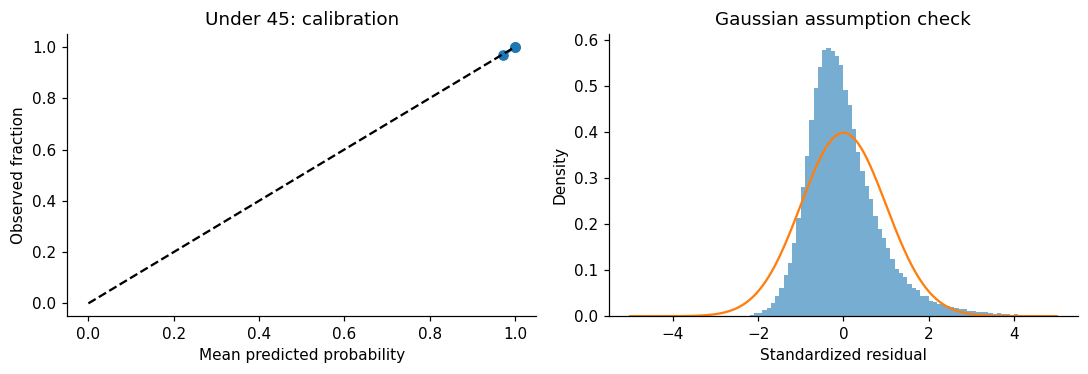

The selected MLP has width **128**. On the held-out test set its
Gaussian NLL is **2.7594**, and its duration RMSE is
**3.968 minutes**. Its under-45 probabilities have
Brier score **0.002831**, log loss
**0.017618**, and accuracy
**99.6626%**. The always-under-45 classifier has accuracy
**99.5543%**. A nominal central 90% Gaussian prediction interval covers
**94.12%** of test trips. This coverage and the residual plot help assess the normal
assumption; a good mean fit alone does not establish reliable tail probabilities.

In [4]:
linear_taxi=Ridge(alpha=1.).fit(Xt,yt)
linear_sigma=max(float(np.sqrt(np.mean((yt-linear_taxi.predict(Xt))**2))),1e-6)
mu_test,sigma_test=gaussian_predict(taxi_model,Xe)
taxi_gaussians={
    'Constant Gaussian':(np.full(len(ye),ym),np.full(len(ye),ys)),
    'Linear mean + constant sigma':(linear_taxi.predict(Xe),np.full(len(ye),linear_sigma)),
    'Heteroscedastic MLP':(mu_test,sigma_test)}
event=(ye<45).astype(int)
def probability_metrics(p):
    return {'Brier':brier_score_loss(event,p),
            'Log loss':log_loss(event,np.clip(p,1e-7,1-1e-7),labels=[0,1]),
            'Accuracy':accuracy_score(event,p>=.5)}
taxi_rows=[]
for name,(m,s) in taxi_gaussians.items():
    p=norm.cdf((45-m)/s)
    taxi_rows.append({'Model':name,'Gaussian NLL':nll_np(ye,m,s),
                      'RMSE (min)':np.sqrt(mean_squared_error(ye,m)),**probability_metrics(p)})
taxi_rows.append({'Model':'Training event frequency',**probability_metrics(np.full(len(ye),np.mean(yt<45)))})
taxi_rows.append({'Model':'Always under 45',**probability_metrics(np.ones(len(ye)))})
taxi_results=pd.DataFrame(taxi_rows).set_index('Model')
display(taxi_results.round(6)); taxi_results.to_csv('q1_results.csv')
p_test=norm.cdf((45-mu_test)/sigma_test)
print(f'Test events: {event.sum():,}/{len(event):,} under 45; {(event==0).sum():,} at least 45.')
observed,predicted=calibration_curve(event,p_test,n_bins=8,strategy='quantile')
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(predicted,observed,'o-'); ax[0].plot([0,1],[0,1],'k--')
ax[0].set(xlabel='Mean predicted probability',ylabel='Observed fraction',title='Under 45: calibration')
residuals=(ye-mu_test)/sigma_test
ax[1].hist(residuals,bins=100,range=(-5,5),density=True,alpha=.6)
grid=np.linspace(-5,5,300); ax[1].plot(grid,norm.pdf(grid))
ax[1].set(xlabel='Standardized residual',ylabel='Density',title='Gaussian assumption check')
showfig('q1_calibration.png')
coverage=np.mean(np.abs(residuals)<=norm.ppf(.95))
display(Markdown(f"""The selected MLP has width **{best_width}**. On the held-out test set its
Gaussian NLL is **{nll_np(ye,mu_test,sigma_test):.4f}**, and its duration RMSE is
**{np.sqrt(mean_squared_error(ye,mu_test)):.3f} minutes**. Its under-45 probabilities have
Brier score **{brier_score_loss(event,p_test):.6f}**, log loss
**{log_loss(event,np.clip(p_test,1e-7,1-1e-7),labels=[0,1]):.6f}**, and accuracy
**{accuracy_score(event,p_test>=.5):.4%}**. The always-under-45 classifier has accuracy
**{event.mean():.4%}**. A nominal central 90% Gaussian prediction interval covers
**{coverage:.2%}** of test trips. This coverage and the residual plot help assess the normal
assumption; a good mean fit alone does not establish reliable tail probabilities."""))

The MLP improves duration RMSE from 7.54 minutes for the linear baseline to 3.97 minutes.
Its Brier score also improves over the empirical-frequency baseline (0.002831 versus 0.004437).
The gain in accuracy is small because 99.55% of the test trips take less than 45 minutes.
The standardized residuals are more concentrated near zero than a standard normal and have a
right tail. The 94.12% coverage of a nominal 90% interval suggests that these intervals are
conservative on average, although that does not establish calibration for every input or tail.
The probability calibration plot uses quantile bins and is dominated by high probabilities,
so it should not be interpreted as strong evidence about rare long-trip cases.

## Problem 2: Categorical encodings

### (a) Cardinalities and splitting
I treat both input columns as categorical, including the numeric-looking CustomerID.
I use a fixed random 70/15/15 split for every model. This evaluates new transactions
from the same population; it does not require all test customers or products to be unseen.
All encoders, scaling parameters, and category vocabularies are learned from training data.

I minimize MSE for $z=\log(1+\mathrm{Quantity})$, which reduces the influence of extreme
orders and rewards relative accuracy. The primary comparison is test MSE on that same
log scale. I also report MAE and RMSE in original quantity units after $\exp(\hat z)-1$,
clipped below at 1. This back-transformation is a point prediction on the log scale;
it is generally not an estimate of $E[\mathrm{Quantity}\mid X]$ because of Jensen's inequality.

Split sizes: 278546 59689 59689


,Unique categories
StockCode,3665
CustomerID,4339


,Quantity
count,397924.000000
mean,13.021823
std,180.420210
min,1.000000
50%,6.000000
90%,24.000000
99%,120.000000
99.9%,504.000000
max,80995.000000


There are **3,665** stock codes and
**4,339** customers, giving **8,004** one-hot columns.
A dense float32 representation of the full dataset would require roughly
**12.7 GB** before model overhead. Sparse one-hot encoding is feasible
because each row has just two nonzero entries, but dense one-hot inputs to a network are
unnecessarily large. Embeddings provide a compact alternative.

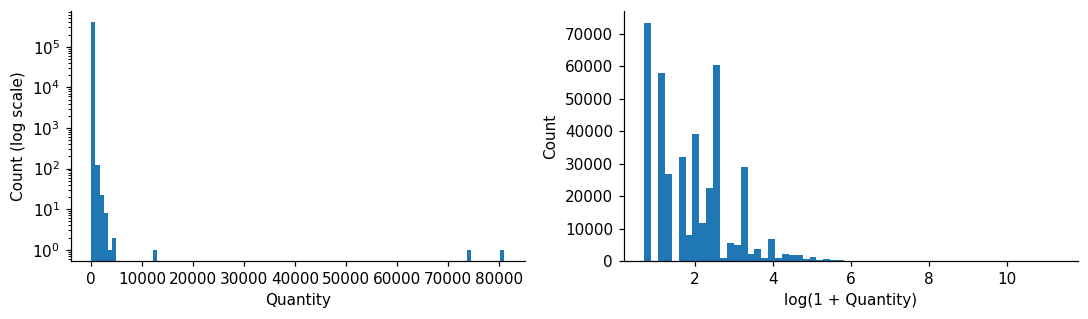

In [5]:
retail=pd.read_csv(DATA/'retail.csv',dtype={'StockCode':str,'CustomerID':str})
cats=['StockCode','CustomerID']
assert not retail.isna().any().any() and (retail.Quantity>0).all()
display(retail[cats].nunique().to_frame('Unique categories'))
display(retail.Quantity.describe(percentiles=[.5,.9,.99,.999]).to_frame())
rt,rr=train_test_split(np.arange(len(retail)),test_size=.30,random_state=SEED)
rv,re=train_test_split(rr,test_size=.50,random_state=SEED)
Rtr,Rva,Rte=[retail.iloc[i].reset_index(drop=True) for i in [rt,rv,re]]
rztr,rzva,rzte=[np.log1p(d.Quantity.to_numpy(np.float64)) for d in [Rtr,Rva,Rte]]
print('Split sizes:',len(Rtr),len(Rva),len(Rte))
k=retail[cats].nunique().sum()
display(Markdown(f"""There are **{retail.StockCode.nunique():,}** stock codes and
**{retail.CustomerID.nunique():,}** customers, giving **{k:,}** one-hot columns.
A dense float32 representation of the full dataset would require roughly
**{len(retail)*k*4/1e9:.1f} GB** before model overhead. Sparse one-hot encoding is feasible
because each row has just two nonzero entries, but dense one-hot inputs to a network are
unnecessarily large. Embeddings provide a compact alternative."""))
fig,ax=plt.subplots(1,2,figsize=(10,3))
ax[0].hist(retail.Quantity,bins=100);ax[0].set_yscale('log');ax[0].set(xlabel='Quantity',ylabel='Count (log scale)')
ax[1].hist(np.log1p(retail.Quantity),bins=60);ax[1].set(xlabel='log(1 + Quantity)',ylabel='Count')
showfig('q2_quantity.png')

### (b) Target encoding
For each category I compute its mean **raw quantity** from training observations,
smoothed toward the training global mean with 20 pseudo-observations:
\[
\operatorname{TE}(c)=\frac{\sum_{i:x_i=c}y_i+20\bar y}{n_c+20}.
\]
I then apply $\log(1+\operatorname{TE})$ to reduce skew in these two numeric input
features. This still uses mean-quantity target encoding; it is distinct from taking
the mean of log quantities. Unknown categories receive the relevant training global mean.

Training encodings are generated by five-fold cross-fitting: each row is encoded using
only the other four folds. Validation and test encodings use the full training set.
This avoids directly including a row's own target in its encoded features. I fit gradient
boosted trees to the two encoded inputs and choose the iteration count by validation
log-scale MSE. The smoothing strength and tree settings are fixed in advance.

In [6]:
class MeanTargetEncoder:
    def __init__(self,smoothing=20.): self.smoothing=smoothing
    def fit(self,X,y):
        self.global_mean=float(np.mean(y));self.maps={}
        for c in cats:
            stats=pd.DataFrame({'key':X[c].to_numpy(),'y':y}).groupby('key').y.agg(['sum','count'])
            self.maps[c]=(stats['sum']+self.smoothing*self.global_mean)/(stats['count']+self.smoothing)
        return self
    def transform(self,X):
        a=np.column_stack([X[c].map(self.maps[c]).fillna(self.global_mean).to_numpy() for c in cats])
        return np.log1p(a).astype(np.float32)

te_train=np.zeros((len(Rtr),2),dtype=np.float32)
for learn,hold in KFold(5,shuffle=True,random_state=SEED).split(Rtr):
    enc=MeanTargetEncoder().fit(Rtr.iloc[learn],Rtr.Quantity.to_numpy()[learn])
    te_train[hold]=enc.transform(Rtr.iloc[hold])
encoder=MeanTargetEncoder().fit(Rtr,Rtr.Quantity.to_numpy())
te_val,te_test=encoder.transform(Rva),encoder.transform(Rte)
te_models={}; te_sweep=[]
for iterations in [100,200,400]:
    reg=HistGradientBoostingRegressor(max_iter=iterations,max_leaf_nodes=15,learning_rate=.05,
            l2_regularization=1.,early_stopping=False,random_state=SEED).fit(te_train,rztr)
    te_models[iterations]=reg
    te_sweep.append({'iterations':iterations,'train_log_MSE':mean_squared_error(rztr,reg.predict(te_train)),
                     'val_log_MSE':mean_squared_error(rzva,reg.predict(te_val))})
te_sweep=pd.DataFrame(te_sweep);display(te_sweep)
te_best=int(te_sweep.loc[te_sweep.val_log_MSE.idxmin(),'iterations'])
te_model=te_models[te_best]

,iterations,train_log_MSE,val_log_MSE
0,100,0.403192,0.400321
1,200,0.401211,0.401008
2,400,0.399115,0.401940


### (c) Embedding model
Each feature has a learned 16-dimensional embedding. The two embeddings are concatenated
and passed through a 64-unit ReLU layer, a 32-unit ReLU layer, and a scalar output for
log quantity. Index 0 is reserved for unknown categories and has a fixed zero embedding.
Training vocabulary indices start at 1. I use Adam, weight decay, and early stopping on
validation log-scale MSE. The 16-dimensional embedding choice is fixed, not selected on test data.

### (d) Combining target encodings and embeddings
The combined model uses the same architecture and training settings, with the two
standardized target-encoded values appended to the embeddings. Its training values
use the same cross-fitted encodings as part (b). Feature scaling uses the cross-fitted
training values only. This allows a fair comparison with the embedding-only network.

StockCode unseen validation/test rows: 45 51
CustomerID unseen validation/test rows: 19 16
retail combined=False, epoch=5, val log MSE=0.3494
retail combined=False, epoch=10, val log MSE=0.3042
retail combined=False, epoch=15, val log MSE=0.2955
retail combined=False, epoch=20, val log MSE=0.2884
retail combined=False, epoch=25, val log MSE=0.2848
retail combined=False, epoch=30, val log MSE=0.2850
retail combined=True, epoch=5, val log MSE=0.3444
retail combined=True, epoch=10, val log MSE=0.3022
retail combined=True, epoch=15, val log MSE=0.2852
retail combined=True, epoch=20, val log MSE=0.2767
retail combined=True, epoch=25, val log MSE=0.2756
retail combined=True, epoch=30, val log MSE=0.2745
retail combined=True, epoch=35, val log MSE=0.2775


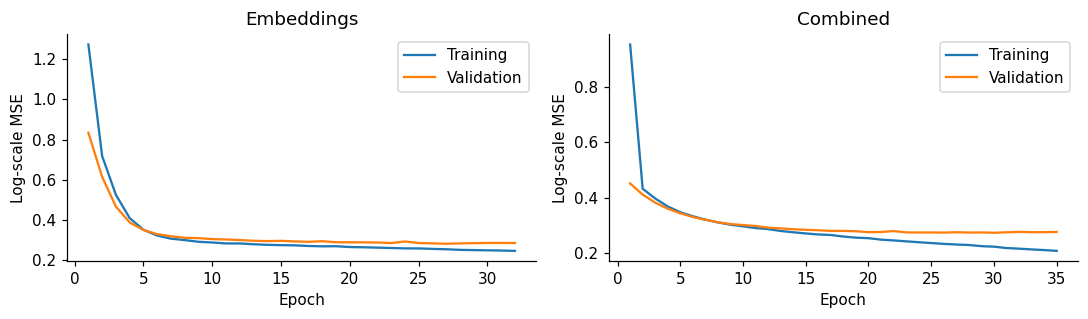

In [7]:
vocab={c:{v:i+1 for i,v in enumerate(sorted(Rtr[c].unique()))} for c in cats}
def category_indices(df):
    return np.column_stack([df[c].map(vocab[c]).fillna(0).to_numpy(np.int64) for c in cats])
ci_train,ci_val,ci_test=[category_indices(d) for d in [Rtr,Rva,Rte]]
for c in cats:
    print(c,'unseen validation/test rows:',(~Rva[c].isin(vocab[c])).sum(),(~Rte[c].isin(vocab[c])).sum())
te_scaler=StandardScaler().fit(te_train)
te_train_s,te_val_s,te_test_s=[te_scaler.transform(a).astype(np.float32) for a in [te_train,te_val,te_test]]

class RetailNet(nn.Module):
    def __init__(self,combined=False,dim=16):
        super().__init__();self.combined=combined
        self.embeddings=nn.ModuleList([nn.Embedding(len(vocab[c])+1,dim,padding_idx=0) for c in cats])
        self.net=nn.Sequential(nn.Linear(2*dim+(2 if combined else 0),64),nn.ReLU(),
                               nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,idx,te):
        a=torch.cat([e(idx[:,j]) for j,e in enumerate(self.embeddings)],dim=1)
        if self.combined: a=torch.cat([a,te],dim=1)
        return self.net(a).squeeze(1)

def retail_predict(model,idx,te):
    model.eval();out=[]
    with torch.no_grad():
        for j in range(0,len(idx),8192):
            out.append(model(torch.as_tensor(idx[j:j+8192],device=DEVICE),
                    torch.as_tensor(te[j:j+8192],device=DEVICE)).cpu().numpy())
    return np.concatenate(out)

def train_retail(combined,epochs=35,patience=5):
    seed_all(); model=RetailNet(combined).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-5)
    xx=torch.from_numpy(ci_train).to(DEVICE); te=torch.from_numpy(te_train_s).to(DEVICE)
    zz=torch.tensor(rztr,dtype=torch.float32,device=DEVICE)
    state=None;best=np.inf;stale=0;history=[]
    for epoch in range(epochs):
        model.train(); total=0.
        for ids in torch.randperm(len(xx),device=DEVICE).split(2048):
            optimizer.zero_grad(); loss=F.mse_loss(model(xx[ids],te[ids]),zz[ids])
            loss.backward();optimizer.step();total+=len(ids)*loss.item()
        val=mean_squared_error(rzva,retail_predict(model,ci_val,te_val_s))
        history.append((epoch+1,total/len(xx),val))
        if val<best-1e-5: best=val;state=copy.deepcopy(model.state_dict());stale=0
        else: stale+=1
        if (epoch+1)%5==0: print(f'retail combined={combined}, epoch={epoch+1}, val log MSE={val:.4f}',flush=True)
        if stale>=patience:break
    model.load_state_dict(state)
    return model,pd.DataFrame(history,columns=['epoch','train_log_MSE','val_log_MSE'])

embedding_model,embedding_history=train_retail(False)
combined_model,combined_history=train_retail(True)
fig,ax=plt.subplots(1,2,figsize=(10,3))
for a,h,title in zip(ax,[embedding_history,combined_history],['Embeddings','Combined']):
    a.plot(h.epoch,h.train_log_MSE,label='Training');a.plot(h.epoch,h.val_log_MSE,label='Validation')
    a.set(xlabel='Epoch',ylabel='Log-scale MSE',title=title);a.legend()
showfig('q2_training.png')

### (e) Test results and interpretation
The next cell evaluates each selected model on the same untouched test split, without
using those results to change any settings. The constant-log-mean baseline is learned
from training data. Original-scale errors can be dominated by a handful of huge orders,
so they answer a different question from log-scale MSE.

In [8]:
retail_predictions={
    'Constant log mean':np.full(len(Rte),rztr.mean()),
    'Target encoding + trees':te_model.predict(te_test),
    'Embeddings':retail_predict(embedding_model,ci_test,te_test_s),
    'Combined':retail_predict(combined_model,ci_test,te_test_s)}
retail_rows=[]
for name,zpred in retail_predictions.items():
    raw=np.maximum(1,np.expm1(zpred))
    assert np.isfinite(raw).all()
    retail_rows.append({'Model':name,'Test log MSE':mean_squared_error(rzte,zpred),
                       'Test MAE':mean_absolute_error(Rte.Quantity,raw),
                       'Test RMSE':np.sqrt(mean_squared_error(Rte.Quantity,raw))})
retail_results=pd.DataFrame(retail_rows).set_index('Model');display(retail_results.round(6))
retail_results.to_csv('q2_results.csv')
winner=retail_results['Test log MSE'].idxmin()
display(Markdown(f"""On this split, **{winner}** has the lowest test log-scale MSE,
**{retail_results.loc[winner,'Test log MSE']:.4f}**. Target encoding gives
**{retail_results.loc['Target encoding + trees','Test log MSE']:.4f}**, embeddings give
**{retail_results.loc['Embeddings','Test log MSE']:.4f}**, and the combined model gives
**{retail_results.loc['Combined','Test log MSE']:.4f}**.

An embedding is a learned vector for a category. Categories that help predict similar
quantities can acquire similar representations. The network can also learn customer–product
interactions, rather than reducing each category to a single mean. Target encoding supplies
a strong low-dimensional summary, but loses variation beyond that mean. Combining both
representations can help if their information is complementary; it is not guaranteed to win
because of redundancy, noise in category means, and the additional parameters. Cross-fitted
training encodings and full-training test encodings also have slightly different noise levels.

These comparisons describe these fixed models and this split. They do not prove that one
encoding is universally best: the target-encoding model uses boosted trees while the other
two use neural networks, and no repeated-split uncertainty estimate is reported. The large
raw-scale RMSE reflects the heavy tail and the log-scale training objective."""))

,Test log MSE,Test MAE,Test RMSE
Model,,,
Constant log mean,0.996641,10.206148,41.362794
Target encoding + trees,0.401479,7.026189,33.506339
Embeddings,0.284166,6.064809,29.504465
Combined,0.276346,5.928946,29.160279


On this split, **Combined** has the lowest test log-scale MSE,
**0.2763**. Target encoding gives
**0.4015**, embeddings give
**0.2842**, and the combined model gives
**0.2763**.

An embedding is a learned vector for a category. Categories that help predict similar
quantities can acquire similar representations. The network can also learn customer–product
interactions, rather than reducing each category to a single mean. Target encoding supplies
a strong low-dimensional summary, but loses variation beyond that mean. Combining both
representations can help if their information is complementary; it is not guaranteed to win
because of redundancy, noise in category means, and the additional parameters. Cross-fitted
training encodings and full-training test encodings also have slightly different noise levels.

These comparisons describe these fixed models and this split. They do not prove that one
encoding is universally best: the target-encoding model uses boosted trees while the other
two use neural networks, and no repeated-split uncertainty estimate is reported. The large
raw-scale RMSE reflects the heavy tail and the log-scale training objective.

The combined model improves on both alternatives on all three reported test metrics:
log-scale MSE is 0.2763, original-scale MAE is 5.93, and original-scale RMSE is 29.16.
Its log-scale MSE is about 2.8% lower than the embedding-only model and 31.2% lower than
target encoding with trees. This is consistent with the category averages supplying a useful
summary alongside the learned interactions. The fixed split also illustrates the instability
of heavy-tailed data: maximum quantities are 80,995 in training, 1,930 in validation, and
3,114 in test. The test metrics therefore do not establish performance on orders as extreme
as the largest training observations.

## Problem 3: Random Kitchen Sinks and a one-hidden-layer MLP

### (a) Training data visualization
The provided training and validation splits are kept unchanged. The test file contains
only coordinates, so a test MSE cannot be calculated. I visualize the 600 observed training
responses as colored points; the later fitted surfaces use the same color limits.

Shapes: (600, 2) (200, 2) (200, 2)


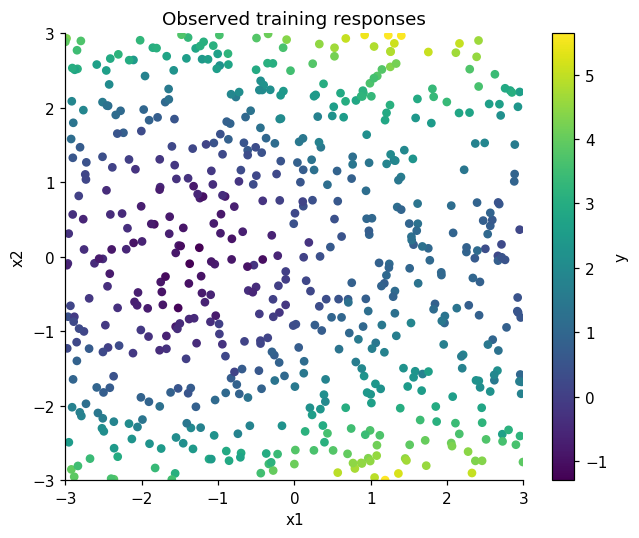

In [9]:
train3=pd.read_csv(DATA/'train.csv');val3=pd.read_csv(DATA/'val.csv');test3=pd.read_csv(DATA/'test.csv')
assert list(test3.columns)==['x1','x2']
X3t,y3t=train3[['x1','x2']].to_numpy(),train3.y.to_numpy()
X3v,y3v=val3[['x1','x2']].to_numpy(),val3.y.to_numpy()
X3e=test3[['x1','x2']].to_numpy()
print('Shapes:',X3t.shape,X3v.shape,X3e.shape)
clim=(float(y3t.min()),float(y3t.max()))
plt.figure(figsize=(6,5));plt.scatter(*X3t.T,c=y3t,s=22,cmap='viridis',vmin=clim[0],vmax=clim[1])
plt.xlim(-3,3);plt.ylim(-3,3);plt.xlabel('x1');plt.ylabel('x2');plt.colorbar(label='y')
plt.title('Observed training responses');showfig('q3_training_data.png')

### (b) Random Kitchen Sinks with ridge regression
I sample $w_j\sim N(0,I/\sigma^2)$ and $b_j\sim U[0,2\pi]$, and use both
$\sin(w_j^Tx+b_j)$ and $\cos(w_j^Tx+b_j)$, interleaved as in the assignment.
Here $D=2h$ counts the total number of sine and cosine features. The features are fixed;
only the ridge coefficients and intercept are fit. I minimize
\[
\sum_i(y_i-\beta_0-z_i^T\beta)^2+\lambda\|\beta\|_2^2,
\]
leaving the intercept unpenalized. Features are not additionally normalized, so $\lambda$
is interpreted on this explicitly stated scale.

I sweep the kernel scale $\sigma\in\{0.15,0.3,0.5,0.8,1.2,2,3\}$ with
$D=512$ and $\lambda=0.01$ held fixed. The same base Gaussian draws and phases are used
at every scale, so the comparison does not unnecessarily change the random features.
Training and validation MSE are plotted separately. Only validation MSE selects the scale.

,sigma,train_MSE,val_MSE
0,0.15,0.008411,0.275646
1,0.30,0.019091,0.083315
2,0.50,0.025747,0.044386
3,0.80,0.028867,0.043463
4,1.20,0.029998,0.039316
5,2.00,0.031490,0.037653
6,3.00,0.032375,0.036723


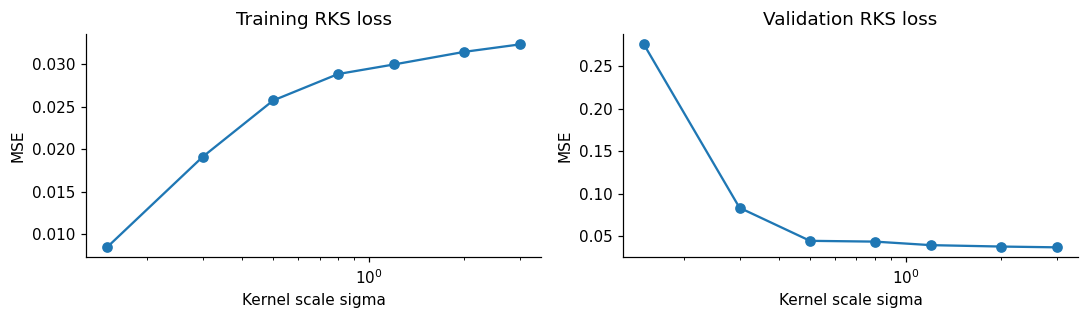

In [10]:
class RandomKitchenSinks:
    def __init__(self,D=512,sigma=1.,ridge_lambda=.01,seed=SEED):
        if D%2 or D<2:raise ValueError('D must be positive and even')
        if sigma<=0 or ridge_lambda<=0:raise ValueError('sigma and lambda must be positive')
        self.D=D;self.sigma=sigma;self.ridge_lambda=ridge_lambda;self.seed=seed
    def _features(self,X):
        angle=np.asarray(X)@self.W+self.b
        return np.stack([np.sin(angle),np.cos(angle)],axis=-1).reshape(len(X),self.D)
    def fit(self,X,y):
        rng=np.random.default_rng(self.seed)
        self.W=rng.normal(size=(X.shape[1],self.D//2))/self.sigma
        self.b=rng.uniform(0,2*np.pi,size=self.D//2)
        self.ridge=Ridge(alpha=self.ridge_lambda,fit_intercept=True,solver='cholesky')
        self.ridge.fit(self._features(X),y)
        return self
    def predict(self,X):return self.ridge.predict(self._features(X))

rks_sweep=[]
for sigma in [.15,.3,.5,.8,1.2,2.,3.]:
    m=RandomKitchenSinks(sigma=sigma).fit(X3t,y3t)
    rks_sweep.append({'sigma':sigma,'train_MSE':mean_squared_error(y3t,m.predict(X3t)),
                      'val_MSE':mean_squared_error(y3v,m.predict(X3v))})
rks_sweep=pd.DataFrame(rks_sweep);display(rks_sweep)
best_sigma=float(rks_sweep.loc[rks_sweep.val_MSE.idxmin(),'sigma'])
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,col,label in zip(axes,['train_MSE','val_MSE'],['Training','Validation']):
    ax.plot(rks_sweep.sigma,rks_sweep[col],'o-');ax.set_xscale('log')
    ax.set(xlabel='Kernel scale sigma',ylabel='MSE',title=label+' RKS loss')
showfig('q3_rks_sweep.png')

### (c) One-hidden-layer MLP
I use exactly one hidden layer with a tanh activation and a linear output:
$f(x)=v^T\tanh(Wx+b)+c$. Tanh is a smooth nonlinear activation; it is not an
additional hidden layer. I sweep widths $\{16,32,64,128,256\}$, holding the optimizer,
activation, learning rate (0.005), weight decay ($10^{-5}$), batch size (full training set),
and 2,500-epoch budget fixed. The same seed is reset for each configuration.
Inputs are divided by 3 using the known coordinate bounds, and targets are standardized
using training statistics. All reported MSEs are in the original response units.

For this sweep, the epoch budget is fixed and the final epoch is used for every width;
validation MSE selects only the width. This avoids selecting an extra checkpoint for
each configuration. This finite grid does not establish the best possible MLP.

{'width': 16, 'train_MSE': 0.033492532991817786, 'val_MSE': 0.03658388515850214}
{'width': 32, 'train_MSE': 0.033683341868987436, 'val_MSE': 0.03653330526366034}
{'width': 64, 'train_MSE': 0.03305673412530639, 'val_MSE': 0.03570124455203702}
{'width': 128, 'train_MSE': 0.03324928705009217, 'val_MSE': 0.035680860891436905}
{'width': 256, 'train_MSE': 0.033798873438221556, 'val_MSE': 0.03600079941874055}


,width,train_MSE,val_MSE
0,16,0.033493,0.036584
1,32,0.033683,0.036533
2,64,0.033057,0.035701
3,128,0.033249,0.035681
4,256,0.033799,0.036001


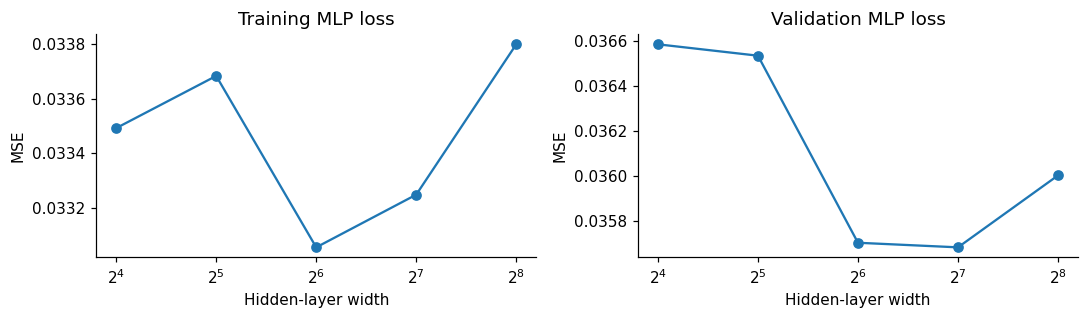

In [11]:
y3mean,y3std=float(y3t.mean()),float(y3t.std())
class OneHiddenMLP(nn.Module):
    def __init__(self,width):
        super().__init__(); self.net=nn.Sequential(nn.Linear(2,width),nn.Tanh(),nn.Linear(width,1))
    def forward(self,x):return self.net(x).squeeze(1)
    def predict(self,X):
        self.eval()
        with torch.no_grad():
            return self(torch.as_tensor(X/3,dtype=torch.float32,device=DEVICE)).cpu().numpy()*y3std+y3mean

def fit_mlp3(width,epochs=2500):
    seed_all();model=OneHiddenMLP(width).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=.005,weight_decay=1e-5)
    x=torch.tensor(X3t/3,dtype=torch.float32,device=DEVICE)
    y=torch.tensor((y3t-y3mean)/y3std,dtype=torch.float32,device=DEVICE)
    for epoch in range(epochs):
        model.train();opt.zero_grad();loss=F.mse_loss(model(x),y);loss.backward();opt.step()
    return model

mlp_sweep=[]
for width in [16,32,64,128,256]:
    m=fit_mlp3(width)
    row={'width':width,'train_MSE':mean_squared_error(y3t,m.predict(X3t)),
         'val_MSE':mean_squared_error(y3v,m.predict(X3v))}
    mlp_sweep.append(row);print(row,flush=True)
mlp_sweep=pd.DataFrame(mlp_sweep);display(mlp_sweep)
best_mlp_width=int(mlp_sweep.loc[mlp_sweep.val_MSE.idxmin(),'width'])
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,col,label in zip(axes,['train_MSE','val_MSE'],['Training','Validation']):
    ax.plot(mlp_sweep.width,mlp_sweep[col],'o-');ax.set_xscale('log',base=2)
    ax.set(xlabel='Hidden-layer width',ylabel='MSE',title=label+' MLP loss')
showfig('q3_mlp_sweep.png')

### (d) Refit, compare, visualize, and export
I refit both selected configurations from scratch on the training set with the same
seed and settings, retaining the original validation set for a meaningful validation
comparison. I do not add validation observations to the refit, since then the reported
validation loss would be an in-sample quantity. Predictions preserve the exact order of
the 200 unlabeled test rows. There is no claimed test MSE.

rks_test_predictions.csv: 200 finite predictions, no header or index
mlp_test_predictions.csv: 200 finite predictions, no header or index


,Selected parameter,Training MSE,Validation MSE
Model,,,
RKS,sigma=3,0.032375,0.036723
One-hidden-layer MLP,width=128,0.033249,0.035681


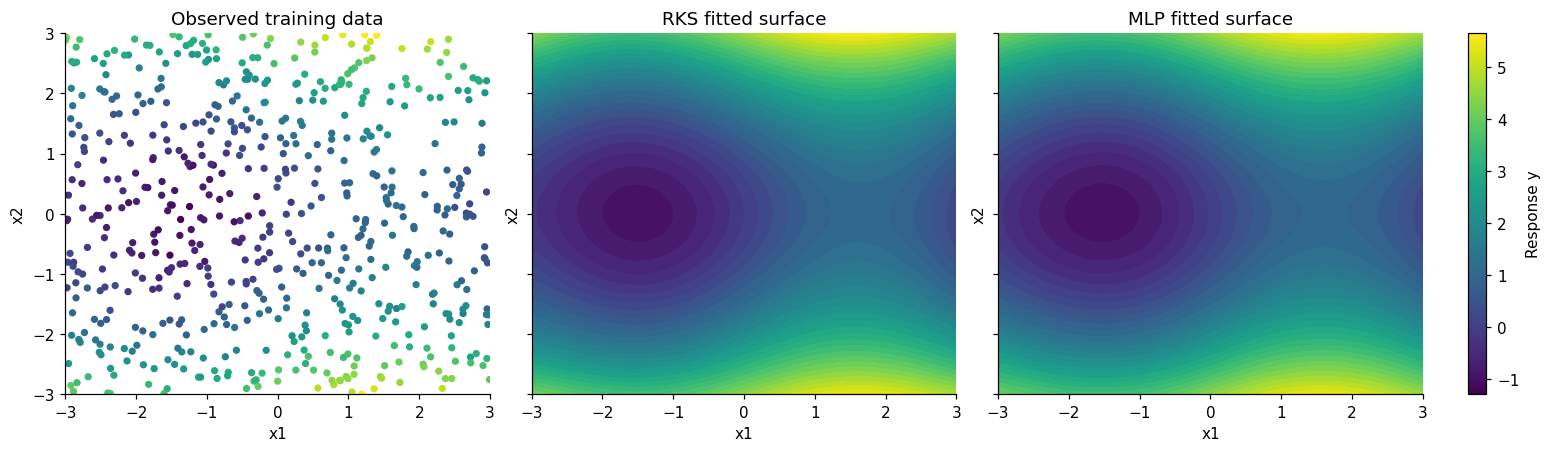

The selected RKS uses **sigma = 3**, with validation MSE
**0.03672**. The selected MLP uses **128**
hidden units, with validation MSE **0.03568**.
**One-hidden-layer MLP** performs better in this experiment. Both learn nonlinear surfaces: RKS combines
fixed sinusoidal features with a ridge fit, while the MLP learns the feature directions and
output weights jointly. The RKS scale controls how rapidly its surface can vary. Too small
a scale can fit local fluctuations and too large a scale can miss structure. MLP width
controls flexibility, but optimization and the fixed training budget also affect its result.
The comparison is specific to these grids and training settings, and the selected validation
scores may be optimistic because validation was used for selection.

In [12]:
rks_final=RandomKitchenSinks(sigma=best_sigma).fit(X3t,y3t)
mlp_final=fit_mlp3(best_mlp_width)
q3_results=pd.DataFrame([
    {'Model':'RKS','Selected parameter':f'sigma={best_sigma:g}',
     'Training MSE':mean_squared_error(y3t,rks_final.predict(X3t)),
     'Validation MSE':mean_squared_error(y3v,rks_final.predict(X3v))},
    {'Model':'One-hidden-layer MLP','Selected parameter':f'width={best_mlp_width}',
     'Training MSE':mean_squared_error(y3t,mlp_final.predict(X3t)),
     'Validation MSE':mean_squared_error(y3v,mlp_final.predict(X3v))}]).set_index('Model')
display(q3_results);q3_results.to_csv('q3_results.csv')
rks_preds=rks_final.predict(X3e).reshape(-1)
mlp_preds=mlp_final.predict(X3e).reshape(-1)
for name,pred in [('rks_test_predictions.csv',rks_preds),('mlp_test_predictions.csv',mlp_preds)]:
    assert len(pred)==len(test3) and np.isfinite(pred).all()
    np.savetxt(name,pred,delimiter=',',fmt='%.10f')
    saved=np.loadtxt(name,delimiter=',')
    assert saved.shape==(len(test3),) and np.allclose(saved,pred,atol=1e-8)
    print(f'{name}: {len(saved)} finite predictions, no header or index')

grid=np.linspace(-3,3,160);gx,gy=np.meshgrid(grid,grid)
gridX=np.column_stack([gx.ravel(),gy.ravel()])
fig,ax=plt.subplots(1,3,figsize=(14,4),sharex=True,sharey=True,layout='constrained')
image=ax[0].scatter(*X3t.T,c=y3t,s=14,vmin=clim[0],vmax=clim[1],cmap='viridis')
ax[0].set_title('Observed training data')
levels=np.linspace(clim[0],clim[1],35)
for a,model,title in zip(ax[1:],[rks_final,mlp_final],['RKS fitted surface','MLP fitted surface']):
    a.contourf(gx,gy,model.predict(gridX).reshape(gx.shape),levels=levels,cmap='viridis',extend='both')
    a.set_title(title)
for a in ax:a.set(xlabel='x1',ylabel='x2',xlim=(-3,3),ylim=(-3,3))
fig.colorbar(image,ax=list(ax),label='Response y',fraction=.025,pad=.03)
plt.savefig(FIG/'q3_surfaces.png',dpi=150,bbox_inches='tight');plt.show();plt.close()
best3=q3_results['Validation MSE'].idxmin()
display(Markdown(f"""The selected RKS uses **sigma = {best_sigma:g}**, with validation MSE
**{q3_results.loc['RKS','Validation MSE']:.5f}**. The selected MLP uses **{best_mlp_width}**
hidden units, with validation MSE **{q3_results.loc['One-hidden-layer MLP','Validation MSE']:.5f}**.
**{best3}** performs better in this experiment. Both learn nonlinear surfaces: RKS combines
fixed sinusoidal features with a ridge fit, while the MLP learns the feature directions and
output weights jointly. The RKS scale controls how rapidly its surface can vary. Too small
a scale can fit local fluctuations and too large a scale can miss structure. MLP width
controls flexibility, but optimization and the fixed training budget also affect its result.
The comparison is specific to these grids and training settings, and the selected validation
scores may be optimistic because validation was used for selection."""))

**Surface comparison.** The training points show a broad valley around $x_2=0$,
with larger responses toward $x_2=-3$ and $x_2=3$. Responses also vary smoothly along
$x_1$: the low region is near $x_1=-1.5$, while values around $x_1=1.5$ are higher.
Both fitted surfaces reproduce these features, including the curved valley and smooth
horizontal variation, rather than chasing the noise in individual training points.
Their surfaces look very similar, which matches the small difference in validation MSE.
The MLP's learned smooth features provide a slightly better fit here, but the difference
is too small to claim a general advantage without repeated runs or a separate labeled test set.

The RKS sweep shows clear overfitting at the smallest scale: its training MSE is low while
validation MSE is high. Larger scales generalize better on these smooth data. The selected
scale, 3, is the largest value tested, so this is the best configuration within the stated grid,
not a claim that 3 is globally optimal. The MLP's training MSE need not decrease monotonically
with width because the optimization is nonconvex and each model has a fixed training budget.

### Reproducibility and files
The notebook contains all model and preprocessing code. `rks_test_predictions.csv` and
`mlp_test_predictions.csv` are the required prediction submissions. They contain one numeric
value per row, without a header or index. `q1_results.csv`, `q2_results.csv`, and
`q3_results.csv` contain the displayed evaluation tables. Figures are also saved in `figures/`.
No test labels or test scores were used to select model hyperparameters.